# Лабораторная работа №1. Классификация текстов

Цель: сравнить два способа получения общего вектора текста из эмбеддингов токенов — `mean pooling` и использование вектора токена `CLS`. Затем обучить классификатор на датасете AG News и сравнить качество по Accuracy, Precision, Recall и Macro F1.

Ноутбук содержит весь код эксперимента. Подробная теория остаётся в `REPORT.md`, а здесь приведены только пояснения, необходимые для запуска.

## Порядок работы

1. Подготавливаем сбалансированные обучающую и валидационную выборки.
2. Токенизируем тексты.
3. Для каждого текста получаем скрытые состояния токенов из MiniLM.
4. Сравниваем mean pooling и CLS pooling.
5. Обучаем линейный классификатор и оцениваем его на тестовой выборке.

Для установки зависимостей один раз выполните `%pip install -r requirements.txt`. Желательно выбрать Python-интерпретатор из `lab_1/.venv`.

## 1. Настройка путей и кэшей

In [1]:
from pathlib import Path
import os

import random
from collections import defaultdict
from dataclasses import dataclass

import torch
from datasets import Dataset, DatasetDict, load_dataset
from torch.utils.data import TensorDataset
from transformers import PreTrainedTokenizerBase

G:\ITMO\LLM_2026\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
def find_lab_root(lab_name: str) -> Path:
    current = Path.cwd().resolve()
    if current.name == lab_name:
        return current
    candidate = current / lab_name
    if candidate.exists():
        return candidate
    raise FileNotFoundError(
        f"Не найдена папка {lab_name}. Откройте ноутбук из корня проекта или из папки лабораторной."
    )


LAB_ROOT = find_lab_root("lab_1")
PROJECT_ROOT = LAB_ROOT.parent

# Кэши и временные файлы остаются на диске с проектом
os.environ["HF_HOME"] = str(LAB_ROOT / ".cache" / "huggingface")
os.environ["HF_DATASETS_CACHE"] = str(LAB_ROOT / ".cache" / "huggingface" / "datasets")
os.environ["TRANSFORMERS_CACHE"] = str(LAB_ROOT / ".cache" / "huggingface" / "hub")
os.environ["TMP"] = str(LAB_ROOT / ".tmp")
os.environ["TEMP"] = str(LAB_ROOT / ".tmp")
os.environ["NLTK_DATA"] = str(LAB_ROOT / ".cache" / "nltk_data")

print(f"Папка лабораторной: {LAB_ROOT}")

LABEL_NAMES = ["World", "Sports", "Business", "Sci/Tech"]

Папка лабораторной: G:\ITMO\LLM_2026\lab_1


## 2. Подготовка данных

In [3]:

import random
from collections import defaultdict
from dataclasses import dataclass

import torch
from datasets import Dataset, DatasetDict, load_dataset
from torch.utils.data import TensorDataset
from transformers import PreTrainedTokenizerBase


LABEL_NAMES = ["World", "Sports", "Business", "Sci/Tech"]


@dataclass(frozen=True)
class DatasetSizes:
    train_per_class: int = 3_000
    validation_per_class: int = 1_000


def _indices_by_label(dataset: Dataset) -> dict[int, list[int]]:
    result: dict[int, list[int]] = defaultdict(list)
    for index, label in enumerate(dataset["label"]):
        result[int(label)].append(index)
    return result


def build_stratified_splits(seed: int, sizes: DatasetSizes) -> DatasetDict:
    """Загружает AG News и создаёт сбалансированные train/validation выборки.

    Официальная тестовая выборка не изменяется. Валидационные примеры берутся
    только из train, поэтому test остаётся независимым от обучения и настройки.
    """

    raw = load_dataset("fancyzhx/ag_news")
    train_source = raw["train"]
    grouped = _indices_by_label(train_source)
    rng = random.Random(seed)

    train_indices: list[int] = []
    validation_indices: list[int] = []
    requested = sizes.train_per_class + sizes.validation_per_class

    for label in sorted(grouped):
        label_indices = grouped[label]
        if len(label_indices) < requested:
            raise ValueError(
                f"В классе {label} находится {len(label_indices)} примеров, "
                f"но запрошено {requested}."
            )
        rng.shuffle(label_indices)
        train_indices.extend(label_indices[: sizes.train_per_class])
        validation_indices.extend(
            label_indices[sizes.train_per_class : requested]
        )

    rng.shuffle(train_indices)
    rng.shuffle(validation_indices)

    return DatasetDict(
        train=train_source.select(train_indices),
        validation=train_source.select(validation_indices),
        test=raw["test"],
    )


def tokenize_split(
    split: Dataset,
    tokenizer: PreTrainedTokenizerBase,
    max_length: int,
) -> TensorDataset:
    encoded = tokenizer(
        list(split["text"]),
        padding="max_length",
        truncation=True,
        max_length=max_length,
        return_tensors="pt",
    )
    labels = torch.tensor(list(split["label"]), dtype=torch.long)
    return TensorDataset(encoded["input_ids"], encoded["attention_mask"], labels)

## 3. Метрики классификации

In [4]:

from dataclasses import dataclass

import numpy as np
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
)


@dataclass(frozen=True)
class ClassificationMetrics:
    accuracy: float
    precision_macro: float
    recall_macro: float
    f1_macro: float

    def as_dict(self) -> dict[str, float]:
        return {
            "accuracy": self.accuracy,
            "precision_macro": self.precision_macro,
            "recall_macro": self.recall_macro,
            "f1_macro": self.f1_macro,
        }


def calculate_metrics(
    targets: list[int],
    predictions: list[int],
) -> tuple[ClassificationMetrics, np.ndarray]:
    metrics = ClassificationMetrics(
        accuracy=accuracy_score(targets, predictions),
        precision_macro=precision_score(
            targets, predictions, average="macro", zero_division=0
        ),
        recall_macro=recall_score(
            targets, predictions, average="macro", zero_division=0
        ),
        f1_macro=f1_score(targets, predictions, average="macro", zero_division=0),
    )
    matrix = confusion_matrix(targets, predictions)
    return metrics, matrix

## 4. Модель и два варианта pooling

In [5]:

from typing import Literal

import torch
from torch import nn
from transformers import AutoModel


PoolingType = Literal["mean", "cls"]


class TextClassifier(nn.Module):
    """Классификатор текста с выбираемой стратегией объединения токенов."""

    def __init__(
        self,
        model_name: str,
        num_classes: int,
        pooling: PoolingType,
        dropout: float = 0.1,
    ) -> None:
        super().__init__()
        if pooling not in {"mean", "cls"}:
            raise ValueError(f"Неизвестная стратегия pooling: {pooling}")

        self.encoder = AutoModel.from_pretrained(model_name)
        self.pooling = pooling
        self.dropout = nn.Dropout(dropout)
        self.classifier = nn.Linear(self.encoder.config.hidden_size, num_classes)

    def _pool(
        self,
        token_embeddings: torch.Tensor,
        attention_mask: torch.Tensor,
    ) -> torch.Tensor:
        if self.pooling == "cls":
            return token_embeddings[:, 0]

        # Маска исключает padding-токены из среднего, иначе короткие тексты
        # получали бы вектор, зависящий от количества добавленного padding.
        expanded_mask = attention_mask.unsqueeze(-1).to(token_embeddings.dtype)
        embedding_sum = (token_embeddings * expanded_mask).sum(dim=1)
        valid_token_count = expanded_mask.sum(dim=1).clamp(min=1e-9)
        return embedding_sum / valid_token_count

    def forward(
        self,
        input_ids: torch.Tensor,
        attention_mask: torch.Tensor,
    ) -> torch.Tensor:
        encoder_output = self.encoder(
            input_ids=input_ids,
            attention_mask=attention_mask,
        )
        text_vector = self._pool(
            token_embeddings=encoder_output.last_hidden_state,
            attention_mask=attention_mask,
        )
        return self.classifier(self.dropout(text_vector))

## 5. Обучение, оценка и сохранение результатов

In [6]:

import argparse
import gc
import json
import os
import random
import sys
import time
from dataclasses import asdict, dataclass
from pathlib import Path

import matplotlib
import numpy as np
import pandas as pd
import seaborn as sns
import torch
from sklearn.metrics import classification_report
from torch import nn
from torch.optim import AdamW
from torch.optim.lr_scheduler import LambdaLR
from torch.utils.data import DataLoader, TensorDataset
from tqdm.auto import tqdm
from transformers import AutoTokenizer

matplotlib.use("Agg")
import matplotlib.pyplot as plt



LAB_ROOT = LAB_ROOT
ARTIFACTS_DIR = LAB_ROOT / "artifacts"
CHECKPOINT_DIR = ARTIFACTS_DIR / "checkpoints"


@dataclass(frozen=True)
class ExperimentConfig:
    model_name: str = "sentence-transformers/all-MiniLM-L6-v2"
    seed: int = 42
    train_per_class: int = 3_000
    validation_per_class: int = 1_000
    max_length: int = 128
    batch_size: int = 32
    epochs: int = 2
    learning_rate: float = 2e-5
    weight_decay: float = 0.01
    warmup_ratio: float = 0.1
    dropout: float = 0.1


def parse_args() -> argparse.Namespace:
    parser = argparse.ArgumentParser(
        description="Сравнение mean pooling и CLS pooling на AG News."
    )
    parser.add_argument("--epochs", type=int, default=2)
    parser.add_argument("--batch-size", type=int, default=32)
    parser.add_argument("--train-per-class", type=int, default=3_000)
    parser.add_argument("--validation-per-class", type=int, default=1_000)
    parser.add_argument("--max-length", type=int, default=128)
    parser.add_argument("--seed", type=int, default=42)
    parser.add_argument(
        "--pooling",
        choices=["mean", "cls", "both"],
        default="both",
        help="Запустить одну стратегию pooling или сравнить обе.",
    )
    return parser.parse_args()


def set_seed(seed: int) -> None:
    os.environ["PYTHONHASHSEED"] = str(seed)
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)


def linear_warmup_decay(
    optimizer: AdamW,
    total_steps: int,
    warmup_ratio: float,
) -> LambdaLR:
    warmup_steps = max(1, int(total_steps * warmup_ratio))

    def lr_lambda(current_step: int) -> float:
        # Сначала learning rate линейно растёт, затем плавно уменьшается до нуля.
        if current_step < warmup_steps:
            return float(current_step + 1) / float(warmup_steps)
        remaining_steps = max(1, total_steps - warmup_steps)
        return max(
            0.0,
            float(total_steps - current_step) / float(remaining_steps),
        )

    return LambdaLR(optimizer, lr_lambda)


def make_loader(
    dataset: TensorDataset,
    batch_size: int,
    shuffle: bool,
    seed: int,
) -> DataLoader:
    generator = torch.Generator()
    generator.manual_seed(seed)
    return DataLoader(
        dataset,
        batch_size=batch_size,
        shuffle=shuffle,
        num_workers=0,
        pin_memory=torch.cuda.is_available(),
        generator=generator if shuffle else None,
    )


def evaluate(
    model: TextClassifier,
    loader: DataLoader,
    device: torch.device,
    loss_fn: nn.Module,
) -> tuple[float, ClassificationMetrics, np.ndarray, list[int], list[int]]:
    model.eval()
    total_loss = 0.0
    targets: list[int] = []
    predictions: list[int] = []

    with torch.inference_mode():
        for input_ids, attention_mask, labels in loader:
            input_ids = input_ids.to(device, non_blocking=True)
            attention_mask = attention_mask.to(device, non_blocking=True)
            labels = labels.to(device, non_blocking=True)

            logits = model(input_ids=input_ids, attention_mask=attention_mask)
            total_loss += loss_fn(logits, labels).item() * labels.size(0)
            targets.extend(labels.cpu().tolist())
            predictions.extend(logits.argmax(dim=-1).cpu().tolist())

    metrics, matrix = calculate_metrics(targets, predictions)
    return total_loss / len(loader.dataset), metrics, matrix, targets, predictions


def train_one_pooling(
    pooling: PoolingType,
    config: ExperimentConfig,
    tokenized: dict[str, TensorDataset],
    raw_test_texts: list[str],
    device: torch.device,
) -> tuple[dict, list[dict]]:
    set_seed(config.seed)
    model = TextClassifier(
        model_name=config.model_name,
        num_classes=len(LABEL_NAMES),
        pooling=pooling,
        dropout=config.dropout,
    ).to(device)

    train_loader = make_loader(
        tokenized["train"], config.batch_size, shuffle=True, seed=config.seed
    )
    validation_loader = make_loader(
        tokenized["validation"], config.batch_size, shuffle=False, seed=config.seed
    )
    test_loader = make_loader(
        tokenized["test"], config.batch_size, shuffle=False, seed=config.seed
    )

    optimizer = AdamW(
        model.parameters(),
        lr=config.learning_rate,
        weight_decay=config.weight_decay,
    )
    total_steps = len(train_loader) * config.epochs
    scheduler = linear_warmup_decay(
        optimizer,
        total_steps=total_steps,
        warmup_ratio=config.warmup_ratio,
    )
    loss_fn = nn.CrossEntropyLoss()
    use_amp = device.type == "cuda"
    # Mixed precision уменьшает расход видеопамяти; GradScaler защищает fp16
    # градиенты от численного обнуления.
    scaler = torch.amp.GradScaler("cuda", enabled=use_amp)

    best_validation_f1 = -1.0
    checkpoint_path = CHECKPOINT_DIR / f"{pooling}_best.pt"
    history: list[dict] = []
    start_time = time.perf_counter()

    for epoch in range(1, config.epochs + 1):
        model.train()
        running_loss = 0.0
        progress = tqdm(
            train_loader,
            desc=f"{pooling}: epoch {epoch}/{config.epochs}",
            leave=False,
        )

        for input_ids, attention_mask, labels in progress:
            input_ids = input_ids.to(device, non_blocking=True)
            attention_mask = attention_mask.to(device, non_blocking=True)
            labels = labels.to(device, non_blocking=True)
            optimizer.zero_grad(set_to_none=True)

            with torch.autocast(
                device_type=device.type,
                dtype=torch.float16,
                enabled=use_amp,
            ):
                logits = model(input_ids=input_ids, attention_mask=attention_mask)
                loss = loss_fn(logits, labels)

            scaler.scale(loss).backward()
            scaler.unscale_(optimizer)
            torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
            scaler.step(optimizer)
            scaler.update()
            scheduler.step()

            running_loss += loss.item() * labels.size(0)
            progress.set_postfix(loss=f"{loss.item():.4f}")

        train_loss = running_loss / len(train_loader.dataset)
        validation_loss, validation_metrics, _, _, _ = evaluate(
            model, validation_loader, device, loss_fn
        )
        epoch_record = {
            "pooling": pooling,
            "epoch": epoch,
            "train_loss": train_loss,
            "validation_loss": validation_loss,
            **{
                f"validation_{name}": value
                for name, value in validation_metrics.as_dict().items()
            },
        }
        history.append(epoch_record)
        print(
            f"[{pooling}] epoch={epoch} "
            f"train_loss={train_loss:.4f} "
            f"val_loss={validation_loss:.4f} "
            f"val_macro_f1={validation_metrics.f1_macro:.4f}"
        )

        if validation_metrics.f1_macro > best_validation_f1:
            # На test оценивается не последняя эпоха, а лучшая по validation F1.
            best_validation_f1 = validation_metrics.f1_macro
            torch.save(
                {
                    "model_state_dict": model.state_dict(),
                    "pooling": pooling,
                    "config": asdict(config),
                    "validation_metrics": validation_metrics.as_dict(),
                },
                checkpoint_path,
            )

    checkpoint = torch.load(checkpoint_path, map_location=device, weights_only=True)
    model.load_state_dict(checkpoint["model_state_dict"])
    test_loss, test_metrics, matrix, targets, predictions = evaluate(
        model, test_loader, device, loss_fn
    )
    elapsed_seconds = time.perf_counter() - start_time

    report = classification_report(
        targets,
        predictions,
        target_names=LABEL_NAMES,
        output_dict=True,
        zero_division=0,
    )
    errors = []
    for index, (target, prediction) in enumerate(zip(targets, predictions)):
        if target != prediction:
            errors.append(
                {
                    "text": raw_test_texts[index],
                    "target": LABEL_NAMES[target],
                    "prediction": LABEL_NAMES[prediction],
                }
            )
        if len(errors) == 30:
            break

    result = {
        "pooling": pooling,
        "best_validation_f1_macro": best_validation_f1,
        "test_loss": test_loss,
        **test_metrics.as_dict(),
        "elapsed_seconds": elapsed_seconds,
        "confusion_matrix": matrix.tolist(),
        "classification_report": report,
        "sample_errors": errors,
    }

    del model, optimizer, scheduler, scaler
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()

    return result, history


def save_plots(results: list[dict], history: list[dict]) -> None:
    plots_dir = ARTIFACTS_DIR / "plots"
    plots_dir.mkdir(parents=True, exist_ok=True)
    sns.set_theme(style="whitegrid")

    comparison_rows = []
    for result in results:
        for metric in ["precision_macro", "recall_macro", "f1_macro", "accuracy"]:
            comparison_rows.append(
                {
                    "Pooling": result["pooling"].upper(),
                    "Metric": metric.replace("_macro", "").replace("_", " ").title(),
                    "Value": result[metric],
                }
            )
    comparison_df = pd.DataFrame(comparison_rows)
    plt.figure(figsize=(9, 5))
    chart = sns.barplot(
        data=comparison_df,
        x="Metric",
        y="Value",
        hue="Pooling",
    )
    chart.set_ylim(0, 1)
    chart.set_title("AG News: сравнение стратегий pooling")
    chart.set_ylabel("Значение метрики")
    for container in chart.containers:
        chart.bar_label(container, fmt="%.3f", padding=3, fontsize=9)
    plt.tight_layout()
    plt.savefig(plots_dir / "metrics_comparison.png", dpi=180)
    plt.close()

    history_df = pd.DataFrame(history)
    plt.figure(figsize=(9, 5))
    sns.lineplot(
        data=history_df,
        x="epoch",
        y="validation_f1_macro",
        hue="pooling",
        marker="o",
    )
    lower_bound = max(0.0, history_df["validation_f1_macro"].min() - 0.005)
    upper_bound = min(1.0, history_df["validation_f1_macro"].max() + 0.005)
    plt.ylim(lower_bound, upper_bound)
    plt.xticks(sorted(history_df["epoch"].unique()))
    plt.ylabel("Macro F1")
    plt.xlabel("Эпоха")
    plt.title("Macro F1 на validation по эпохам")
    plt.tight_layout()
    plt.savefig(plots_dir / "validation_f1_history.png", dpi=180)
    plt.close()

    for result in results:
        matrix = np.asarray(result["confusion_matrix"])
        plt.figure(figsize=(7, 6))
        sns.heatmap(
            matrix,
            annot=True,
            fmt="d",
            cmap="Blues",
            xticklabels=LABEL_NAMES,
            yticklabels=LABEL_NAMES,
        )
        plt.xlabel("Предсказанный класс")
        plt.ylabel("Истинный класс")
        plt.title(f"Матрица ошибок: {result['pooling'].upper()} pooling")
        plt.tight_layout()
        plt.savefig(
            plots_dir / f"confusion_matrix_{result['pooling']}.png",
            dpi=180,
        )
        plt.close()


def run_experiment(args: argparse.Namespace) -> None:
    """Запускает эксперимент с явно переданными параметрами."""

    config = ExperimentConfig(
        seed=args.seed,
        train_per_class=args.train_per_class,
        validation_per_class=args.validation_per_class,
        max_length=args.max_length,
        batch_size=args.batch_size,
        epochs=args.epochs,
    )
    set_seed(config.seed)
    ARTIFACTS_DIR.mkdir(parents=True, exist_ok=True)
    CHECKPOINT_DIR.mkdir(parents=True, exist_ok=True)

    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    print(f"Python: {sys.version.split()[0]}")
    print(f"PyTorch: {torch.__version__}")
    print(f"Device: {device}")
    if device.type == "cuda":
        print(f"GPU: {torch.cuda.get_device_name(0)}")

    raw = build_stratified_splits(
        seed=config.seed,
        sizes=DatasetSizes(
            train_per_class=config.train_per_class,
            validation_per_class=config.validation_per_class,
        ),
    )
    tokenizer = AutoTokenizer.from_pretrained(config.model_name)
    tokenized = {
        split_name: tokenize_split(split, tokenizer, config.max_length)
        for split_name, split in raw.items()
    }
    print(
        "Dataset sizes: "
        + ", ".join(f"{name}={len(split)}" for name, split in raw.items())
    )

    pooling_strategies: list[PoolingType]
    if args.pooling == "both":
        pooling_strategies = ["mean", "cls"]
    else:
        pooling_strategies = [args.pooling]

    results: list[dict] = []
    complete_history: list[dict] = []
    for pooling in pooling_strategies:
        result, history = train_one_pooling(
            pooling=pooling,
            config=config,
            tokenized=tokenized,
            raw_test_texts=raw["test"]["text"],
            device=device,
        )
        results.append(result)
        complete_history.extend(history)

    payload = {
        "config": asdict(config),
        "environment": {
            "python": sys.version,
            "torch": torch.__version__,
            "device": str(device),
            "gpu": torch.cuda.get_device_name(0) if device.type == "cuda" else None,
        },
        "dataset": {
            "name": "fancyzhx/ag_news",
            "labels": LABEL_NAMES,
            "train_size": len(raw["train"]),
            "validation_size": len(raw["validation"]),
            "test_size": len(raw["test"]),
        },
        "results": results,
    }
    (ARTIFACTS_DIR / "results.json").write_text(
        json.dumps(payload, ensure_ascii=False, indent=2),
        encoding="utf-8",
    )
    pd.DataFrame(complete_history).to_csv(
        ARTIFACTS_DIR / "training_history.csv", index=False
    )

    comparison_columns = [
        "pooling",
        "precision_macro",
        "recall_macro",
        "f1_macro",
        "accuracy",
        "best_validation_f1_macro",
        "test_loss",
        "elapsed_seconds",
    ]
    pd.DataFrame(results)[comparison_columns].to_csv(
        ARTIFACTS_DIR / "comparison.csv", index=False
    )
    save_plots(results, complete_history)

    print("\nИтоговые метрики на test")
    print(pd.DataFrame(results)[comparison_columns].to_string(index=False))
    print(f"\nАртефакты сохранены в: {ARTIFACTS_DIR}")


def main() -> None:
    run_experiment(parse_args())

## 6. Запуск эксперимента

Полный запуск обучает обе модели и может занять заметное время. По умолчанию ячейка не повторяет обучение, потому что итоговые артефакты уже сохранены.

In [7]:
# Параметры полного эксперимента видны прямо в ноутбуке.
EXPERIMENT_ARGS = argparse.Namespace(
    epochs=2,
    batch_size=32,
    train_per_class=3_000,
    validation_per_class=1_000,
    max_length=128,
    seed=42,
    pooling="both",
)

RUN_TRAINING = False

if RUN_TRAINING:
    run_experiment(EXPERIMENT_ARGS)
else:
    print("Обучение пропущено. Ниже загружаются сохранённые результаты.")

Обучение пропущено. Ниже загружаются сохранённые результаты.


## 7. Полученные результаты

,pooling,precision_macro,recall_macro,f1_macro,accuracy,best_validation_f1_macro,test_loss,elapsed_seconds
0,mean,0.905606,0.905921,0.905698,0.905921,0.909043,0.277735,49.001405
1,cls,0.901572,0.901184,0.900813,0.901184,0.910685,0.290200,47.895852


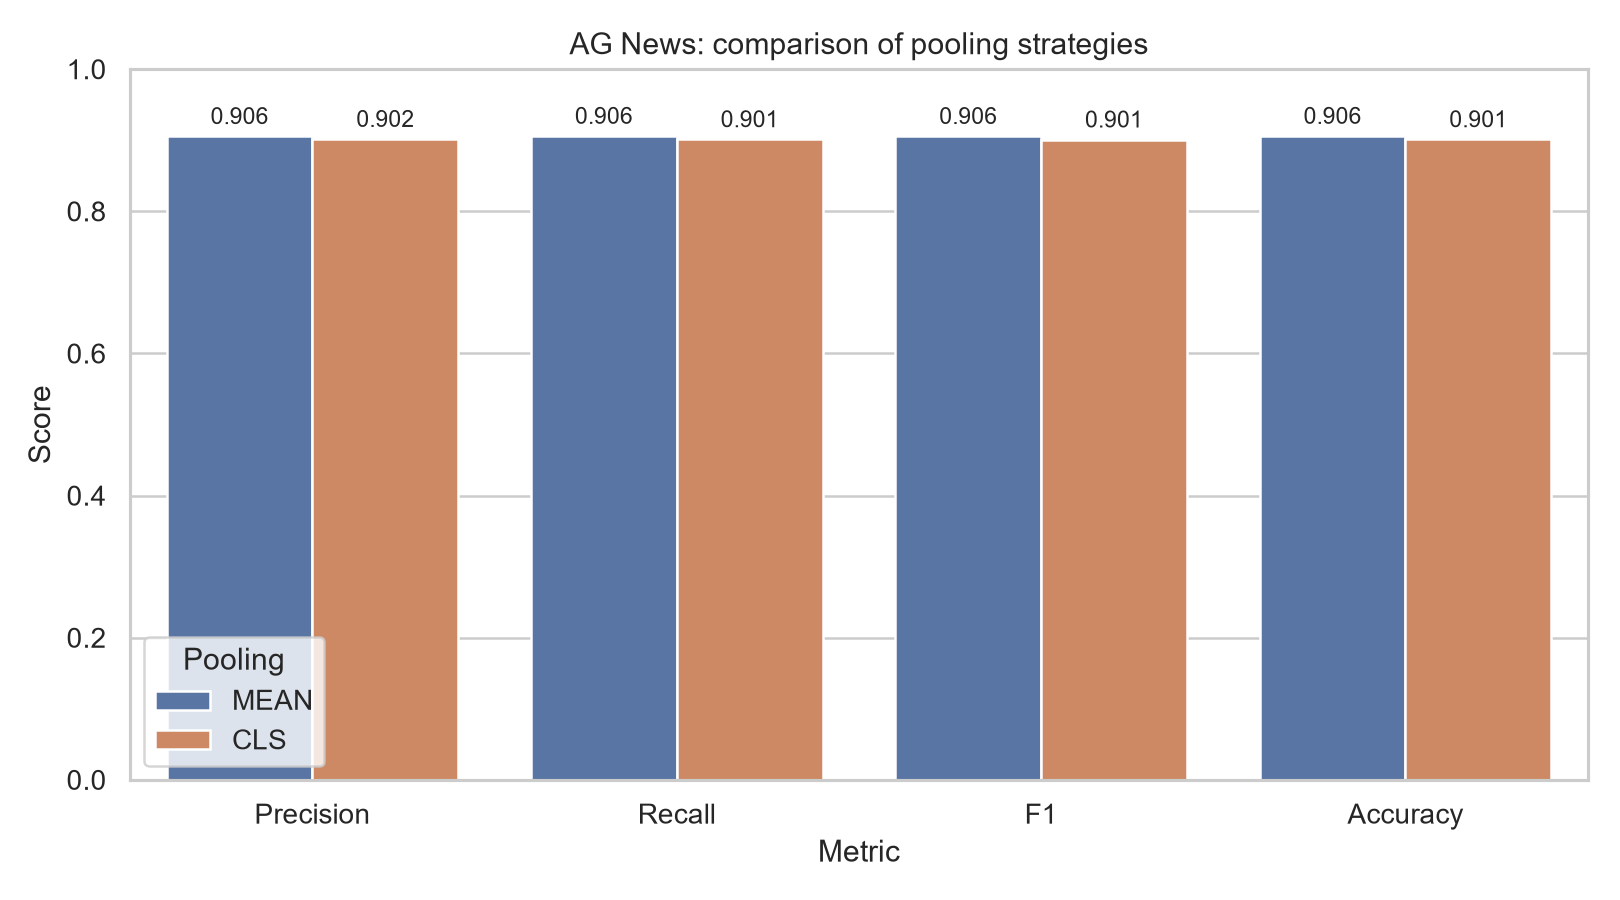

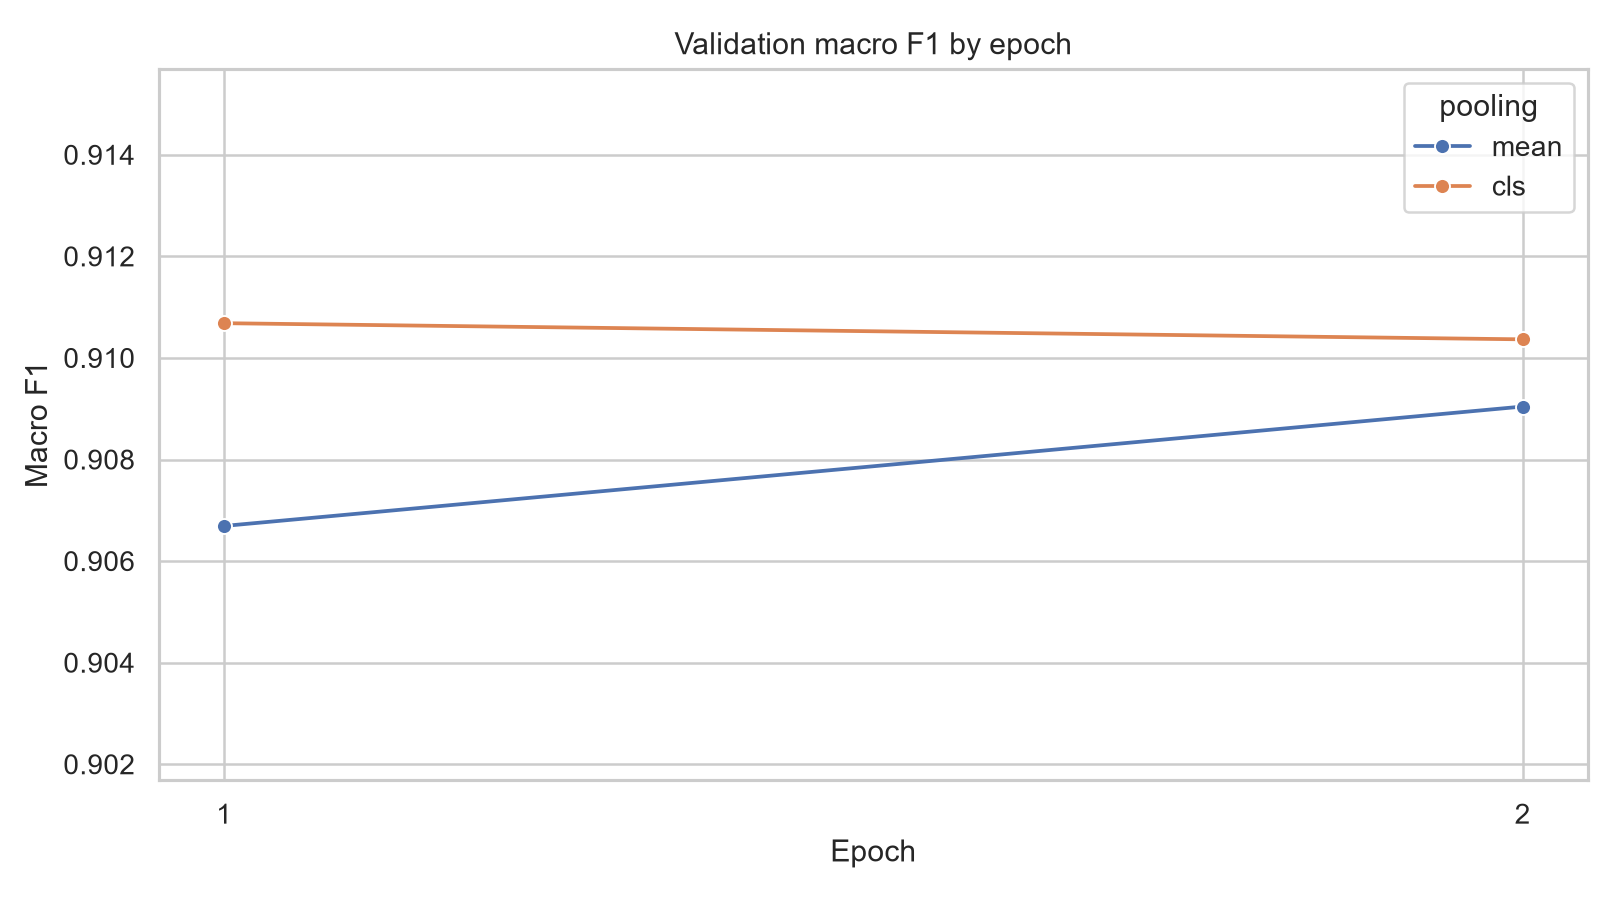

In [8]:
from IPython.display import Image, display

comparison = pd.read_csv(ARTIFACTS_DIR / "comparison.csv")
display(comparison)
display(Image(filename=str(ARTIFACTS_DIR / "plots" / "metrics_comparison.png")))
display(Image(filename=str(ARTIFACTS_DIR / "plots" / "validation_f1_history.png")))

## Вывод

Обе стратегии pooling решают задачу классификации хорошо. Итоговое сравнение нужно делать по Macro F1 и Accuracy: эти значения показывают качество сразу по всем четырём классам. Точные числа выводятся из сохранённого `comparison.csv` в предыдущей ячейке.